# Tutorial 14_A


In [1]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


## 1. Prepare the dataset

In [2]:
# Our own dataset (first sentence is the one you asked for)
sentences = [
    "Irsa live in Swabi",
    "Barack Obama was born in Hawaii",
    "Google is based in Mountain View",
    "Ali lives in Lahore",
    "Sara works in Islamabad",
    "Microsoft is based in Redmond",
    "Ahmed lives in Peshawar",
    "Amazon is based in Seattle",
]

# One label per word (labels must match the number of words!)
labels = [
    ["PERSON", "O", "O", "LOCATION"],
    ["PERSON", "PERSON", "O", "O", "O", "LOCATION"],
    ["ORGANIZATION", "O", "O", "O", "LOCATION", "LOCATION"],
    ["PERSON", "O", "O", "LOCATION"],
    ["PERSON", "O", "O", "LOCATION"],
    ["ORGANIZATION", "O", "O", "O", "LOCATION"],
    ["PERSON", "O", "O", "LOCATION"],
    ["ORGANIZATION", "O", "O", "O", "LOCATION"],
]

for s, l in zip(sentences, labels):
    assert len(s.split()) == len(l), f"Length mismatch: {s}"

## 2. Tokenize, pad and encode the labels

In [3]:
# Vocabulary (0 = padding, 1 = unknown word)
word2idx = {"<PAD>": 0, "<UNK>": 1}
for s in sentences:
    for w in s.lower().split():
        if w not in word2idx:
            word2idx[w] = len(word2idx)

tag2idx = {"O": 0, "PERSON": 1, "LOCATION": 2, "ORGANIZATION": 3}
idx2tag = {i: t for t, i in tag2idx.items()}
PAD_TAG = -100   # ignored by the loss

max_len = max(len(s.split()) for s in sentences)

def encode_sentence(s):
    ids = [word2idx.get(w, 1) for w in s.lower().split()]
    return ids + [0] * (max_len - len(ids))          # post-padding

def encode_labels(l):
    ids = [tag2idx[t] for t in l]
    return ids + [PAD_TAG] * (max_len - len(ids))

X = torch.tensor([encode_sentence(s) for s in sentences])
y = torch.tensor([encode_labels(l) for l in labels])
print("X shape:", X.shape, "| y shape:", y.shape)
print("Vocab size:", len(word2idx))

X shape: torch.Size([8, 6]) | y shape: torch.Size([8, 6])
Vocab size: 28


## 3. Build the RNN model

In [4]:
class NERRNN(nn.Module):
    def __init__(self, vocab_size, n_tags, emb_dim=50, hidden_units=50, dropout=0.1):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=0)   # words -> dense vectors
        self.rnn = nn.RNN(emb_dim, hidden_units, batch_first=True)          # Simple RNN layer
        self.dropout = nn.Dropout(dropout)                                  # avoid overfitting
        self.fc = nn.Linear(hidden_units, n_tags)                           # prediction at each time step

    def forward(self, x):
        out = self.embedding(x)        # (batch, seq, emb)
        out, _ = self.rnn(out)         # (batch, seq, hidden)  -> like return_sequences=True
        out = self.dropout(out)
        return self.fc(out)            # (batch, seq, n_tags)  (softmax is inside the loss)

## 4. Train the model

In [5]:
def train_model(hidden_units=50, epochs=50, lr=0.01, emb_dim=50, batch_size=2, verbose=True):
    model = NERRNN(len(word2idx), len(tag2idx), emb_dim, hidden_units).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_TAG)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)

    losses = []
    for epoch in range(epochs):
        model.train()
        total = 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits.view(-1, len(tag2idx)), yb.view(-1))
            loss.backward()
            optimizer.step()
            total += loss.item()
        losses.append(total / len(loader))
        if verbose and (epoch + 1) % 10 == 0:
            print(f"Epoch {epoch+1}/{epochs} - loss: {losses[-1]:.4f}")
    return model, losses

def accuracy(model):
    model.eval()
    with torch.no_grad():
        pred = model(X.to(device)).argmax(-1).cpu()
    mask = y != PAD_TAG
    return (pred[mask] == y[mask]).float().mean().item()

model, losses = train_model(hidden_units=50, epochs=50, lr=0.01)
print("Training accuracy:", round(accuracy(model), 3))

Epoch 10/50 - loss: 0.0041
Epoch 20/50 - loss: 0.0011
Epoch 30/50 - loss: 0.0008
Epoch 40/50 - loss: 0.0006
Epoch 50/50 - loss: 0.0005
Training accuracy: 1.0


## 5. Test the model with new sentences

In [6]:
def predict(model, sentence):
    model.eval()
    ids = [word2idx.get(w, 1) for w in sentence.lower().split()]   # unknown words -> <UNK>
    x = torch.tensor([ids]).to(device)
    with torch.no_grad():
        pred = model(x).argmax(-1)[0].cpu().tolist()
    for word, p in zip(sentence.split(), pred):
        print(f"Word: {word:12s} - Predicted Label: {idx2tag[p]}")
    print()

predict(model, "Irsa live in Swabi")        # from training data
predict(model, "Ali lives in Swabi")        # new combination of known words
predict(model, "Sara lives in Peshawar")
predict(model, "Irsa went to Mardan")       # unseen words -> harder for the model

Word: Irsa         - Predicted Label: PERSON
Word: live         - Predicted Label: O
Word: in           - Predicted Label: O
Word: Swabi        - Predicted Label: LOCATION

Word: Ali          - Predicted Label: PERSON
Word: lives        - Predicted Label: O
Word: in           - Predicted Label: O
Word: Swabi        - Predicted Label: LOCATION

Word: Sara         - Predicted Label: PERSON
Word: lives        - Predicted Label: O
Word: in           - Predicted Label: O
Word: Peshawar     - Predicted Label: LOCATION

Word: Irsa         - Predicted Label: PERSON
Word: went         - Predicted Label: O
Word: to           - Predicted Label: O
Word: Mardan       - Predicted Label: O



## 6. Task: change units, epochs and learning rate
We train several configurations and compare loss, accuracy and predictions.

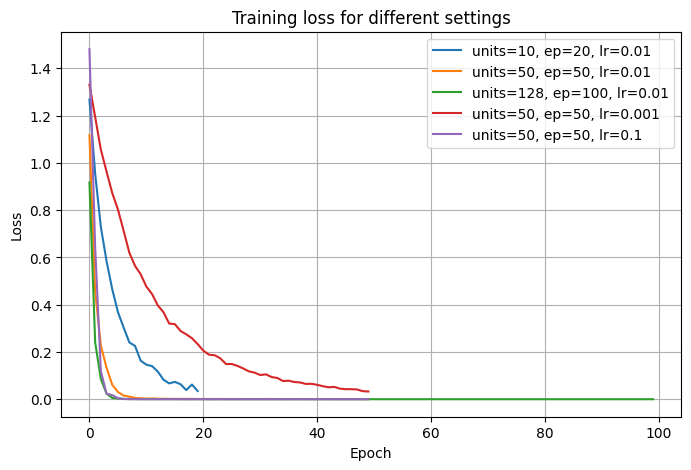

 units  epochs      lr  final loss  accuracy
    10      20    0.01      0.0347      1.00
    50      50    0.01      0.0005      1.00
   128     100    0.01      0.0000      1.00
    50      50   0.001      0.0327      1.00
    50      50     0.1      0.0000      1.00


In [7]:
configs = [
    {"hidden_units": 10,  "epochs": 20,  "lr": 0.01},
    {"hidden_units": 50,  "epochs": 50,  "lr": 0.01},
    {"hidden_units": 128, "epochs": 100, "lr": 0.01},
    {"hidden_units": 50,  "epochs": 50,  "lr": 0.001},
    {"hidden_units": 50,  "epochs": 50,  "lr": 0.1},
]

results = []
plt.figure(figsize=(8, 5))
for cfg in configs:
    torch.manual_seed(42)
    m, l = train_model(**cfg, verbose=False)
    acc = accuracy(m)
    results.append((cfg, l[-1], acc))
    plt.plot(l, label=f"units={cfg['hidden_units']}, ep={cfg['epochs']}, lr={cfg['lr']}")

plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Training loss for different settings")
plt.legend(); plt.grid(True); plt.show()

print(f"{'units':>6} {'epochs':>7} {'lr':>7} {'final loss':>11} {'accuracy':>9}")
for cfg, loss, acc in results:
    print(f"{cfg['hidden_units']:>6} {cfg['epochs']:>7} {cfg['lr']:>7} {loss:>11.4f} {acc:>9.2f}")

In [8]:
# Compare predictions of the best-looking and a weaker setting on the same sentence
test = "Ali lives in Swabi"
for cfg in [{"hidden_units": 10, "epochs": 5, "lr": 0.001}, {"hidden_units": 128, "epochs": 100, "lr": 0.01}]:
    torch.manual_seed(42)
    m, _ = train_model(**cfg, verbose=False)
    print("Config:", cfg)
    predict(m, test)

Config: {'hidden_units': 10, 'epochs': 5, 'lr': 0.001}
Word: Ali          - Predicted Label: PERSON
Word: lives        - Predicted Label: O
Word: in           - Predicted Label: O
Word: Swabi        - Predicted Label: PERSON

Config: {'hidden_units': 128, 'epochs': 100, 'lr': 0.01}
Word: Ali          - Predicted Label: PERSON
Word: lives        - Predicted Label: O
Word: in           - Predicted Label: O
Word: Swabi        - Predicted Label: LOCATION

